<a href="https://colab.research.google.com/github/simoncurchod-lang/2026_Intro_Python/blob/main/FEEDBACK_SIMON_CURCHOD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Reflective Exercise**

## Exercise 22: Antarctic sea ice, summer against winter

Two real snapshots of Antarctic sea ice concentration from NOAA/NSIDC are cached below, as
`path_winter` (1 August 2017) and `path_summer` (31 December 2017). Each holds
`seaice_conc_cdr`, the ice concentration as a fraction from 0 to 1, on a south polar
stereographic grid — its coordinates are 2D `latitude`/`longitude` arrays rather than simple 1D
dimensions, so xarray's own `.plot()` will not label it cleanly.

<img src="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/part-I/_static/1.4-target-seaice.png" alt="Two south polar stereographic maps of Antarctic sea ice concentration, one in austral winter with a wide ice ring and one in austral summer with much less ice" width="100%">

<em>The figure to replicate: the same field on the same projection at two dates, with the land drawn
in grey beneath the ice and one colorbar shared by both panels.</em>


Rebuild it, and say which date shows more ice.

In [1]:
# Pre-supplied: download the data files and cache them locally.
import pooch

path_winter = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    known_hash="sha256:1ff50bca1e6249a9b2fcd9d9466e31bdb5be650243f99c7319ab2ce625b87ce7",
    fname="seaice_conc_daily_sh_f17_20170801_v03r01.nc",
    path=pooch.os_cache("mlees"),
)
path_summer = pooch.retrieve(
    url="https://raw.githubusercontent.com/gse-unil/2026_MLEES_book/main/data/part-I/seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    known_hash="sha256:309418969ad09f42b8104589bcb86de4ed353a5742fef9385baec174c7d55e66",
    fname="seaice_conc_daily_sh_f17_20171231_v03r01.nc",
    path=pooch.os_cache("mlees"),
)

In [2]:
# Your solution here
# Hint: open each file with xr.open_dataset and select the single time step with .isel(time=0)
# Hint: the valid concentration range is 0-1; a few cells carry flag values above 1
#       (land, coastal, missing) -- mask them out first with da.where(da <= 1)
# Hint: build a figure with two ccrs.SouthPolarStereo() axes:
#       plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})
# Hint: ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree()) crops each axes to the
#       Southern Ocean instead of the whole hemisphere
# Hint: since latitude/longitude are 2D, plot with
#       ax.pcolormesh(ds["longitude"], ds["latitude"], masked, transform=ccrs.PlateCarree())
#       rather than xarray's own .plot()
# Hint: pass vmin=0 and vmax=1 to both pcolormesh calls, so a colour means the same
#       concentration in both panels and one colorbar can serve both
# Hint: add cfeature.LAND under the data and gridlines; fig.colorbar(pcm, ax=axes, label=...)
#       takes the whole array of axes and draws one colorbar for both panels

import xarray as xr
import matplotlib.pyplot as plt

# Chargement des fichiers
summer = xr.open_dataset(path_summer).isel(time=0)
winter = xr.open_dataset(path_winter).isel(time=0)

# Création d'un masque qui garde que les valeurs en dessous de 1
mask_sum_sum = summer.where(summer<=1)
mask_win_win = winter.where(winter<=1)


UFuncTypeError: ufunc 'less_equal' did not contain a loop with signature matching types (<class 'numpy.dtypes.BytesDType'>, <class 'numpy.dtypes._PyLongDType'>) -> None

**Error 1**

One mistake I made was applying the .where() method to the entire xarray.Dataset instead of selecting the specific variable I wanted to work with. My intention was to filter the sea ice concentration values, but I did not fully understand the structure of the dataset and the difference between a Dataset and a DataArray.

To overcome this problem, I examined the structure of the dataset and realised that it contained several variables. I understood that I needed to select the specific variable containing the sea ice concentration data before applying the condition. By selecting seaice_conc_cdr first, I could apply the filtering operation to the appropriate data.

This mistake helped me understand the difference between a Dataset, which can contain several variables, and a DataArray, which represents an individual variable. I learned that it is important to understand the structure of my data before performing operations on it. In the future, I will inspect datasets and select the appropriate variables before applying methods or conditions.

In [4]:
#!pip install cartopy
#import cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 25.3 MB/s  0:00:00


TypeError: 'NaturalEarthFeature' object is not callable

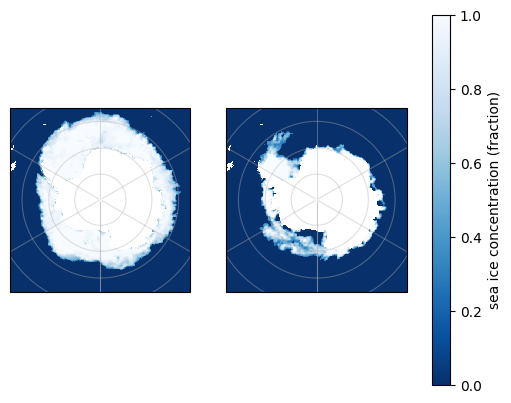

In [5]:
# Your solution here
# Hint: open each file with xr.open_dataset and select the single time step with .isel(time=0)
# Hint: the valid concentration range is 0-1; a few cells carry flag values above 1
#       (land, coastal, missing) -- mask them out first with da.where(da <= 1)
# Hint: build a figure with two ccrs.SouthPolarStereo() axes:
#       plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})
# Hint: ax.set_extent([-180, 180, -90, -55], ccrs.PlateCarree()) crops each axes to the
#       Southern Ocean instead of the whole hemisphere
# Hint: since latitude/longitude are 2D, plot with
#       ax.pcolormesh(ds["longitude"], ds["latitude"], masked, transform=ccrs.PlateCarree())
#       rather than xarray's own .plot()
# Hint: pass vmin=0 and vmax=1 to both pcolormesh calls, so a colour means the same
#       concentration in both panels and one colorbar can serve both
# Hint: add cfeature.LAND under the data and gridlines; fig.colorbar(pcm, ax=axes, label=...)
#       takes the whole array of axes and draws one colorbar for both panels

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Chargement des fichiers
summer = xr.open_dataset(path_summer).isel(time=0)
winter = xr.open_dataset(path_winter).isel(time=0)

# Création d'un masque qui garde que les valeurs en dessous de 1
mask_sum = summer["seaice_conc_cdr"].where(summer["seaice_conc_cdr"]<=1)
mask_win = winter["seaice_conc_cdr"].where(winter["seaice_conc_cdr"]<=1)

fig, ax = plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})

ax[0].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
pcm = ax[0].pcolormesh(winter["longitude"], winter["latitude"], mask_win, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[0].gridlines(alpha=0.4)
fig.colorbar(pcm, ax=ax, label="sea ice concentration (fraction)")

ax[1].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
ax[1].pcolormesh(summer["longitude"], summer["latitude"], mask_sum, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[1].gridlines(alpha=0.4)
ax[1].add_feature(cfeature.LAND())


/tmp/ipykernel_4061/1437041995.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


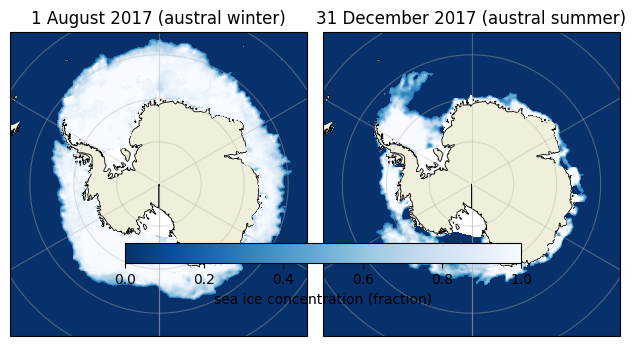

In [7]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Chargement des fichiers
summer = xr.open_dataset(path_summer).isel(time=0)
winter = xr.open_dataset(path_winter).isel(time=0)

# Création d'un masque qui garde que les valeurs en dessous de 1
mask_sum = summer["seaice_conc_cdr"].where(summer["seaice_conc_cdr"]<=1)
mask_win = winter["seaice_conc_cdr"].where(winter["seaice_conc_cdr"]<=1)

fig, ax = plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()})

ax[0].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
pcm = ax[0].pcolormesh(winter["longitude"], winter["latitude"], mask_win, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[0].gridlines(alpha=0.4)
ax[0].set_title("1 August 2017 (austral winter)")
fig.colorbar(pcm, ax=[ax[0], ax[1]], label="sea ice concentration (fraction)", orientation="horizontal", pad=0.05, shrink=0.8)
ax[0].add_feature(cfeature.LAND, edgecolors="k", linewidth=0.6)

ax[1].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
ax[1].pcolormesh(summer["longitude"], summer["latitude"], mask_sum, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[1].gridlines(alpha=0.4)
ax[1].set_title("31 December 2017 (austral summer)")
ax[1].add_feature(cfeature.LAND, edgecolors="k", linewidth=0.6)

plt.tight_layout()
plt.show()

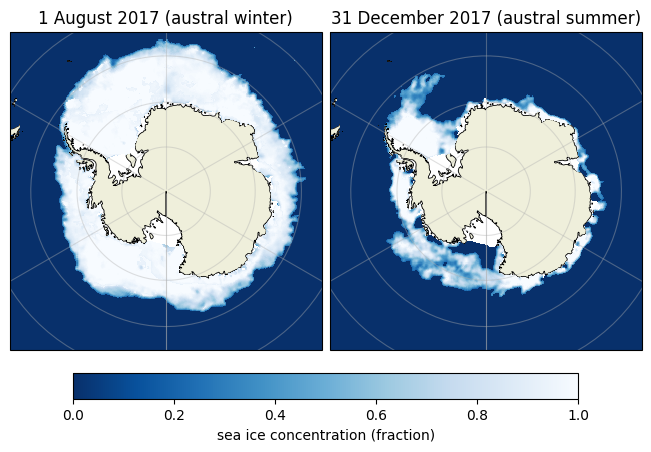

In [8]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Chargement des fichiers
summer = xr.open_dataset(path_summer).isel(time=0)
winter = xr.open_dataset(path_winter).isel(time=0)

# Création d'un masque qui garde que les valeurs en dessous de 1
mask_sum = summer["seaice_conc_cdr"].where(summer["seaice_conc_cdr"]<=1)
mask_win = winter["seaice_conc_cdr"].where(winter["seaice_conc_cdr"]<=1)

fig, ax = plt.subplots(1, 2, subplot_kw={"projection": ccrs.SouthPolarStereo()}, constrained_layout=True)

ax[0].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
pcm = ax[0].pcolormesh(winter["longitude"], winter["latitude"], mask_win, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[0].gridlines(alpha=0.4)
ax[0].set_title("1 August 2017 (austral winter)")
fig.colorbar(pcm, ax=[ax[0], ax[1]], label="sea ice concentration (fraction)", orientation="horizontal", pad=0.05, shrink=0.8)
ax[0].add_feature(cfeature.LAND, edgecolors="k", linewidth=0.6)

ax[1].set_extent([-180, 180, -90, -55], ccrs.PlateCarree())
ax[1].pcolormesh(summer["longitude"], summer["latitude"], mask_sum, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="Blues_r")
ax[1].gridlines(alpha=0.4)
ax[1].set_title("31 December 2017 (austral summer)")
ax[1].add_feature(cfeature.LAND, edgecolors="k", linewidth=0.6)

plt.show()